# Домашнее задание 5

In [1]:
import csv
import json
import math
import re
from datetime import datetime

import matplotlib.pyplot as plt
import pandas as pd

## Классы

In [2]:
# исключения
class InvalidAmountError(ValueError):
    pass


class InvalidOwnerError(ValueError):
    pass


def is_number(value):
    # bool тоже считается int, поэтому отсекаем его отдельно
    if not isinstance(value, (int, float)) or isinstance(value, bool):
        return False
    # nan и inf формально float, но как сумма они не подходят
    return math.isfinite(value)


# читает файл с операциями, формат определяем по расширению
def read_transactions(path):
    if path.endswith('.csv'):
        with open(path, encoding='utf-8', newline='') as f:
            return list(csv.DictReader(f))
    if path.endswith('.json'):
        with open(path, encoding='utf-8') as f:
            return json.load(f)
    raise ValueError(f'Неподдерживаемый формат файла: {path}')

In [3]:
# одна запись в истории счёта
class Transaction:
    # transfer_id заполняется только у переводов, у остальных None
    def __init__(self, operation, amount, balance_after, status,
                 date=None, comment='', transfer_id=None):
        self.date = date or datetime.now()
        self.operation = operation
        self.amount = round(amount, 2)
        self.balance_after = balance_after
        self.status = status
        self.comment = comment
        self.transfer_id = transfer_id

    def __str__(self):
        line = (f'{self.date:%Y-%m-%d %H:%M:%S}  {self.operation:<9}'
                f'{self.amount:>10.2f}  баланс {self.balance_after:>10.2f}  '
                f'{self.status}')
        if self.comment:
            line += f'  ({self.comment})'
        return line

    # нужен для history_df
    def to_dict(self):
        return {
            'date': self.date,
            'operation': self.operation,
            'amount': self.amount,
            'balance_after': self.balance_after,
            'status': self.status,
            'comment': self.comment,
            'transfer_id': self.transfer_id,
        }

In [4]:
# общая логика для всех счетов, наследники меняют только правила
class Account:
    account_type = 'base'
    type_name = 'базовый счёт'
    allowed_operations = ('deposit', 'withdraw')

    # имя и фамилия с заглавной буквы, обе на кириллице или обе на латинице
    owner_pattern = r'^([А-ЯЁ][а-яё]+ [А-ЯЁ][а-яё]+|[A-Z][a-z]+ [A-Z][a-z]+)$'
    date_formats = ('%Y-%m-%d %H:%M:%S', '%d/%m/%Y %H:%M')
    statuses = ('success', 'fail')

    # счётчики общие на все счета, поэтому находятся в классе
    next_number = 1000
    transfer_count = 0

    def __init__(self, owner, balance=0):
        if not isinstance(owner, str) or not re.match(self.owner_pattern,
                                                      owner):
            raise InvalidOwnerError(
                f'Имя владельца должно быть в формате "Имя Фамилия": {owner}'
            )
        if not is_number(balance) or balance < 0:
            raise InvalidAmountError(
                f'Начальный баланс не может быть отрицательным: {balance}'
            )

        self.owner = owner
        self.balance = round(float(balance), 2)
        self.number = f'ACC-{Account.next_number}'
        Account.next_number += 1
        self.history = []

    def __str__(self):
        return (f'{self.number} ({self.type_name}), {self.owner}, '
                f'баланс {self.balance:.2f}')

    def _check_amount(self, amount):
        if not is_number(amount) or amount <= 0:
            raise InvalidAmountError(
                f'Сумма операции должна быть положительным числом: {amount}'
            )

    # любая операция, успешная или нет, попадает в историю
    def _add_record(self, operation, amount, status, date=None,
                    comment='', transfer_id=None):
        record = Transaction(operation, amount, self.balance, status, date,
                             comment, transfer_id)
        self.history.append(record)

    # возвращает причину отказа, если снять нельзя
    def _withdraw_error(self, amount):
        if amount > self.balance:
            return 'недостаточно средств'
        return None

    # зачисление, оно всегда проходит
    def _credit(self, operation, amount, date=None, comment='',
                transfer_id=None):
        self.balance = round(self.balance + amount, 2)
        self._add_record(operation, amount, 'success', date, comment,
                         transfer_id)
        return True

    # списание: если нельзя, баланс не трогаем и пишем fail
    def _debit(self, amount, date=None, comment='', transfer_id=None):
        error = self._withdraw_error(amount)
        if error:
            if comment:
                comment = f'{error}; {comment}'
            else:
                comment = error
            self._add_record('withdraw', amount, 'fail', date, comment,
                             transfer_id)
            return False

        self.balance = round(self.balance - amount, 2)
        self._add_record('withdraw', amount, 'success', date, comment,
                         transfer_id)
        return True

    def deposit(self, amount, date=None):
        self._check_amount(amount)
        return self._credit('deposit', amount, date)

    def withdraw(self, amount, date=None):
        self._check_amount(amount)
        return self._debit(amount, date)

    def transfer(self, other, amount, date=None):
        self._check_amount(amount)
        if other is self:
            raise ValueError('Нельзя перевести деньги на тот же счёт')

        # по этому id обе записи перевода можно найти в двух историях
        Account.transfer_count += 1
        transfer_id = f'TR-{Account.transfer_count:04d}'
        if date is None:
            date = datetime.now()

        # получателю зачисляем только если списание прошло
        if not self._debit(amount, date, f'перевод на {other.number}',
                           transfer_id):
            return False
        other._credit('deposit', amount, date, f'перевод с {self.number}',
                      transfer_id)
        return True

    def get_balance(self):
        return self.balance

    def history_df(self):
        columns = ['date', 'operation', 'amount', 'balance_after', 'status',
                   'comment', 'transfer_id']
        rows = [record.to_dict() for record in self.history]
        return pd.DataFrame(rows, columns=columns)

    def print_history(self):
        print(f'{self.number} ({self.type_name}), владелец {self.owner}')
        for record in self.history:
            print(record)
        print(f'Текущий баланс: {self.balance:.2f}')

    def plot_balance(self):
        df = self.history_df()
        plt.figure(figsize=(10, 4))
        plt.plot(df['date'], df['balance_after'], marker='o')
        plt.title(f'Изменение баланса счёта {self.number}')
        plt.xlabel('Дата и время операции')
        plt.ylabel('Баланс после операции')
        plt.grid(alpha=0.3)
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()

    # последние n успешных операций с суммой от threshold
    def get_large_operations(self, threshold, n):
        large = []
        for record in self.history:
            if record.status == 'success' and record.amount >= threshold:
                large.append(record)
        large.sort(key=lambda record: record.date)
        if n <= 0:
            return []
        return large[-n:]

    # пробуем все форматы дат, если ни один не подошёл - None
    def _parse_date(self, value):
        for fmt in self.date_formats:
            try:
                return datetime.strptime(str(value).strip(), fmt)
            except ValueError:
                pass
        return None

    # проверяет строку из файла, возвращает данные и список ошибок
    def _check_row(self, row):
        errors = []

        account_type = row.get('account_type')
        if account_type != self.account_type:
            errors.append(f'тип счёта {account_type} не подходит')

        operation = row.get('operation')
        if not operation:
            errors.append('пустой тип операции')
        elif operation not in ('deposit', 'withdraw', 'interest'):
            errors.append(f'неизвестный тип операции {operation}')
        elif operation not in self.allowed_operations:
            errors.append(
                f'{operation} недопустим для счёта {self.account_type}')

        amount = row.get('amount')
        if amount is None or str(amount).strip() == '':
            errors.append('пустая сумма')
        else:
            try:
                amount = float(amount)
                if not math.isfinite(amount):
                    errors.append(f'сумма не число: {amount}')
                elif amount <= 0:
                    errors.append('неположительная сумма')
            except ValueError:
                errors.append(f'сумма не число: {amount}')

        date = self._parse_date(row.get('date'))
        if date is None:
            errors.append(f'некорректная дата {row.get("date")}')

        status = row.get('status')
        if status not in self.statuses:
            errors.append(f'некорректный статус {status}')

        operation_data = {'date': date, 'operation': operation,
                          'amount': amount, 'status': status}
        return operation_data, errors

    # source_number - номер счёта в файле
    def load_operations(self, path, source_number):
        report = []
        valid = []
        seen = set()

        rows = read_transactions(path)
        for row_number, row in enumerate(rows, start=1):
            if row.get('account_number') != source_number:
                continue

            operation_data, errors = self._check_row(row)
            # полностью одинаковые строки считаем дублями
            key = tuple(str(value) for value in row.values())
            if key in seen:
                errors.append('дубликат строки')
            seen.add(key)

            report.append({'row': row_number, 'date': row.get('date'),
                           'operation': row.get('operation'),
                           'amount': row.get('amount'),
                           'status': row.get('status'),
                           'accepted': len(errors) == 0,
                           'reason': '; '.join(errors)})
            if not errors:
                valid.append((len(report) - 1, operation_data))

        # операции в файле уже идут по времени, применяем их по порядку
        for index, op in valid:
            if op['status'] == 'fail':
                self._add_record(op['operation'], op['amount'], 'fail',
                                 op['date'], 'загружено из файла')
            elif op['operation'] == 'withdraw':
                # если снять нельзя, _debit сам запишет fail и не тронет баланс
                error = self._withdraw_error(op['amount'])
                if error:
                    report[index]['reason'] = f'записано как fail: {error}'
                self._debit(op['amount'], op['date'])
            else:
                self._credit(op['operation'], op['amount'], op['date'])

        return pd.DataFrame(report)

In [5]:
class CheckingAccount(Account):
    account_type = 'checking'
    type_name = 'расчётный счёт'


class SavingsAccount(Account):
    account_type = 'savings'
    type_name = 'сберегательный счёт'
    allowed_operations = ('deposit', 'withdraw', 'interest')
    withdraw_limit = 0.5

    # сначала своё ограничение в 50%, потом общая проверка остатка
    def _withdraw_error(self, amount):
        if amount > self.balance * self.withdraw_limit:
            return 'нельзя снять больше 50% баланса'
        return super()._withdraw_error(amount)

    # rate в процентах, например 7
    def add_interest(self, rate, date=None):
        if not is_number(rate) or rate <= 0:
            raise ValueError(f'Ставка должна быть положительной: {rate}')
        amount = round(self.balance * rate / 100, 2)
        return self._credit('interest', amount, date, f'ставка {rate}%')

# Задание 1

## Этап 1

In [6]:
acc = CheckingAccount('Илья Иванов', 1000)
print(acc)
print('Тип счёта:', acc.account_type)

acc.deposit(500, datetime(2026, 10, 1, 9, 30))
acc.deposit(1200, datetime(2026, 10, 2, 14, 5))
acc.withdraw(300, datetime(2026, 10, 3, 11, 0))
acc.withdraw(950, datetime(2026, 10, 5, 18, 45))
acc.deposit(250, datetime(2026, 10, 6, 10, 15))

# денег не хватает - баланс не меняется, но попытка попадает в историю
result = acc.withdraw(5000, datetime(2026, 10, 7, 12, 0))
print('Снятие 5000 прошло:', result)

acc.withdraw(100, datetime(2026, 10, 8, 16, 20))
print('Баланс:', acc.get_balance())

ACC-1000 (расчётный счёт), Илья Иванов, баланс 1000.00
Тип счёта: checking
Снятие 5000 прошло: False
Баланс: 1600.0


In [7]:
acc.print_history()

ACC-1000 (расчётный счёт), владелец Илья Иванов
2026-10-01 09:30:00  deposit      500.00  баланс    1500.00  success
2026-10-02 14:05:00  deposit     1200.00  баланс    2700.00  success
2026-10-03 11:00:00  withdraw     300.00  баланс    2400.00  success
2026-10-05 18:45:00  withdraw     950.00  баланс    1450.00  success
2026-10-06 10:15:00  deposit      250.00  баланс    1700.00  success
2026-10-07 12:00:00  withdraw    5000.00  баланс    1700.00  fail  (недостаточно средств)
2026-10-08 16:20:00  withdraw     100.00  баланс    1600.00  success
Текущий баланс: 1600.00


In [8]:
acc.history_df()

,date,operation,amount,balance_after,status,comment,transfer_id
0,2026-10-01 09:30:00,deposit,500,1500.0,success,,None
1,2026-10-02 14:05:00,deposit,1200,2700.0,success,,None
2,2026-10-03 11:00:00,withdraw,300,2400.0,success,,None
3,2026-10-05 18:45:00,withdraw,950,1450.0,success,,None
4,2026-10-06 10:15:00,deposit,250,1700.0,success,,None
5,2026-10-07 12:00:00,withdraw,5000,1700.0,fail,недостаточно средств,None
6,2026-10-08 16:20:00,withdraw,100,1600.0,success,,None


Проверка, что номера не повторяются

In [9]:
accounts = [CheckingAccount('Anna Smith'), SavingsAccount('Пётр Сидоров', 300),
            CheckingAccount('Мария Петрова', 50)]
numbers = [acc.number] + [a.number for a in accounts]
print(numbers)
print('Все номера уникальны:', len(numbers) == len(set(numbers)))

['ACC-1000', 'ACC-1001', 'ACC-1002', 'ACC-1003']
Все номера уникальны: True


## Этап 2

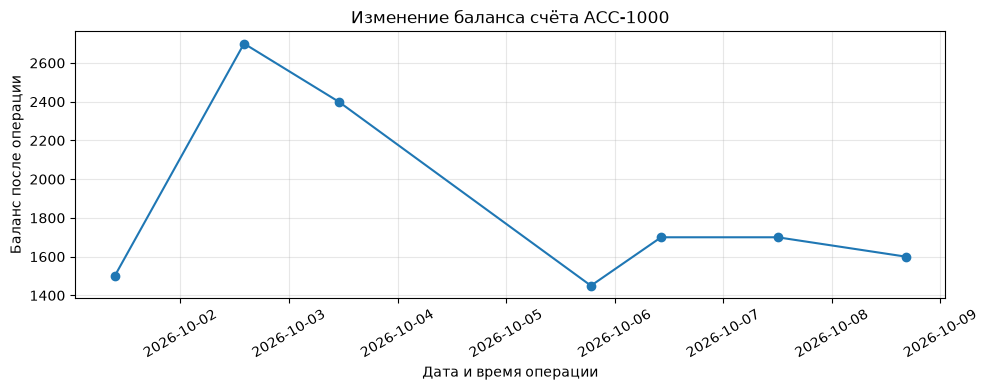

In [10]:
acc.plot_balance()

# Задание 2

In [11]:
checking = CheckingAccount('Ольга Смирнова', 20000)
savings = SavingsAccount('Ivan Petrov', 10000)

for account in (checking, savings):
    print(account, '-', account.account_type, '/', account.type_name)

ACC-1004 (расчётный счёт), Ольга Смирнова, баланс 20000.00 - checking / расчётный счёт
ACC-1005 (сберегательный счёт), Ivan Petrov, баланс 10000.00 - savings / сберегательный счёт


Начисление процентов, ставка 7%

In [12]:
print('До начисления:', savings.get_balance())
savings.add_interest(7, datetime(2026, 10, 1, 10, 0))
print('После начисления 7%:', savings.get_balance())

До начисления: 10000.0
После начисления 7%: 10700.0


Снятие больше 50% баланса

In [13]:
print(savings.withdraw(6000, datetime(2026, 10, 2, 12, 0)))
print(savings.withdraw(5000, datetime(2026, 10, 3, 12, 0)))
savings.print_history()

False
True
ACC-1005 (сберегательный счёт), владелец Ivan Petrov
2026-10-01 10:00:00  interest     700.00  баланс   10700.00  success  (ставка 7%)
2026-10-02 12:00:00  withdraw    6000.00  баланс   10700.00  fail  (нельзя снять больше 50% баланса)
2026-10-03 12:00:00  withdraw    5000.00  баланс    5700.00  success
Текущий баланс: 5700.00


Расчётный счёт, ограничения на снятие нет

In [14]:
checking.deposit(15000, datetime(2026, 10, 1, 9, 0))
checking.withdraw(2500, datetime(2026, 10, 2, 9, 0))
checking.deposit(700, datetime(2026, 10, 3, 9, 0))
checking.withdraw(18000, datetime(2026, 10, 4, 9, 0))
checking.deposit(4300, datetime(2026, 10, 5, 9, 0))
checking.withdraw(400, datetime(2026, 10, 6, 9, 0))
checking.print_history()

ACC-1004 (расчётный счёт), владелец Ольга Смирнова
2026-10-01 09:00:00  deposit    15000.00  баланс   35000.00  success
2026-10-02 09:00:00  withdraw    2500.00  баланс   32500.00  success
2026-10-03 09:00:00  deposit      700.00  баланс   33200.00  success
2026-10-04 09:00:00  withdraw   18000.00  баланс   15200.00  success
2026-10-05 09:00:00  deposit     4300.00  баланс   19500.00  success
2026-10-06 09:00:00  withdraw     400.00  баланс   19100.00  success
Текущий баланс: 19100.00


Последние 3 успешные операции от 2000

In [15]:
for record in checking.get_large_operations(threshold=2000, n=3):
    print(record)

2026-10-02 09:00:00  withdraw    2500.00  баланс   32500.00  success
2026-10-04 09:00:00  withdraw   18000.00  баланс   15200.00  success
2026-10-05 09:00:00  deposit     4300.00  баланс   19500.00  success


Некорректное имя

In [16]:
bad_owners = ['иван петров', 'Ivan', 'Иван Petrov', 'Ivan  Petrov',
              'Ivan Petrov2', '']
for owner in bad_owners:
    try:
        CheckingAccount(owner)
    except InvalidOwnerError as e:
        print('InvalidOwnerError:', e)

InvalidOwnerError: Имя владельца должно быть в формате "Имя Фамилия": иван петров
InvalidOwnerError: Имя владельца должно быть в формате "Имя Фамилия": Ivan
InvalidOwnerError: Имя владельца должно быть в формате "Имя Фамилия": Иван Petrov
InvalidOwnerError: Имя владельца должно быть в формате "Имя Фамилия": Ivan  Petrov
InvalidOwnerError: Имя владельца должно быть в формате "Имя Фамилия": Ivan Petrov2
InvalidOwnerError: Имя владельца должно быть в формате "Имя Фамилия": 


Некорректная сумма

In [17]:
for amount in [0, -100, '500', None, float('nan')]:
    try:
        checking.deposit(amount)
    except InvalidAmountError as e:
        print(repr(amount), '-', e)

try:
    SavingsAccount('Анна Кузнецова', -50)
except InvalidAmountError as e:
    print('InvalidAmountError:', e)

0 - Сумма операции должна быть положительным числом: 0
-100 - Сумма операции должна быть положительным числом: -100
'500' - Сумма операции должна быть положительным числом: 500
None - Сумма операции должна быть положительным числом: None
nan - Сумма операции должна быть положительным числом: nan
InvalidAmountError: Начальный баланс не может быть отрицательным: -50


Перевод между счетами

In [18]:
sender = SavingsAccount('Елена Волкова', 8000)
receiver = CheckingAccount('Дмитрий Орлов', 1000)

print(sender.transfer(receiver, 3000, datetime(2026, 10, 10, 15, 0)))
# 4000 из 5000 - больше половины, перевод отклоняется
print(sender.transfer(receiver, 4000, datetime(2026, 10, 11, 15, 0)))

print(sender, receiver, sep='\n')

True
False
ACC-1006 (сберегательный счёт), Елена Волкова, баланс 5000.00
ACC-1007 (расчётный счёт), Дмитрий Орлов, баланс 4000.00


In [19]:
pd.concat([sender.history_df().assign(account=sender.number),
           receiver.history_df().assign(account=receiver.number)])

,date,operation,amount,balance_after,status,comment,transfer_id,account
0,2026-10-10 15:00:00,withdraw,3000,5000.0,success,перевод на ACC-1007,TR-0001,ACC-1006
1,2026-10-11 15:00:00,withdraw,4000,5000.0,fail,нельзя снять больше 50% баланса; перевод на AC...,TR-0002,ACC-1006
0,2026-10-10 15:00:00,deposit,3000,4000.0,success,перевод с ACC-1006,TR-0001,ACC-1007


# Задание 3

Начальный баланс взял из первой строки по счёту: 2121 - 921 = 1200 для ACC-100001, 1969 - 469 = 1500 для ACC-100002.

Даты вида 28/09/2025 22:17 не отбрасываю, по balance_after видно что это нормальные операции.

In [20]:
path = '../data/data_task5/transactions_dirty.csv'

loaded_checking = CheckingAccount('Сергей Козлов', 1200)
checking_report = loaded_checking.load_operations(path, 'ACC-100001')

loaded_savings = SavingsAccount('Natalia Morozova', 1500)
savings_report = loaded_savings.load_operations(path, 'ACC-100002')

print(loaded_checking)
print(loaded_savings)

ACC-1008 (расчётный счёт), Сергей Козлов, баланс 4864.00
ACC-1009 (сберегательный счёт), Natalia Morozova, баланс 3991.24


In [21]:
loaded_checking.history_df().head(10)

,date,operation,amount,balance_after,status,comment,transfer_id
0,2025-09-27 22:17:26,deposit,921.0,2121.0,success,,None
1,2025-09-27 22:17:26,deposit,607.0,2728.0,success,,None
2,2025-09-28 22:17:26,deposit,488.0,3216.0,success,,None
3,2025-09-28 22:17:00,deposit,129.0,3345.0,success,,None
4,2025-09-29 22:17:26,deposit,880.0,4225.0,success,,None
5,2025-10-01 22:17:26,withdraw,352.0,3873.0,success,,None
6,2025-10-01 22:17:26,withdraw,65.0,3808.0,success,,None
7,2025-10-01 22:17:26,withdraw,245.0,3563.0,success,,None
8,2025-10-05 22:17:26,deposit,327.0,3890.0,success,,None
9,2025-10-06 22:17:26,withdraw,333.0,3557.0,success,,None


In [22]:
loaded_savings.history_df().tail(10)

,date,operation,amount,balance_after,status,comment,transfer_id
8,2025-10-09 22:17:26,withdraw,170.00,4003.72,success,,None
9,2025-10-09 22:17:26,deposit,622.00,4625.72,success,,None
10,2025-10-10 22:17:26,interest,306.26,4931.98,success,,None
11,2025-10-12 22:17:26,withdraw,278.00,4653.98,success,,None
12,2025-10-13 22:17:26,withdraw,440.00,4213.98,success,,None
13,2025-10-14 22:17:26,withdraw,231.00,3982.98,success,,None
14,2025-10-15 22:17:26,interest,274.13,4257.11,success,,None
15,2025-10-17 22:17:26,withdraw,286.00,3971.11,success,,None
16,2025-10-20 22:17:26,interest,302.13,4273.24,success,,None
17,2025-10-23 22:17:26,withdraw,282.00,3991.24,success,,None


Проверка баланса

In [23]:
for account, start in ((loaded_checking, 1200), (loaded_savings, 1500)):
    df = account.history_df()
    ok = df[df['status'] == 'success']
    sign = ok['operation'].map({'deposit': 1, 'interest': 1, 'withdraw': -1})
    expected = round(start + (ok['amount'] * sign).sum(), 2)
    print(account.number, account.get_balance(), expected)

ACC-1008 4864.0 4864.0
ACC-1009 3991.24 3991.24


Загрузка из json

In [24]:
json_checking = CheckingAccount('Сергей Козлов', 1200)
json_report = json_checking.load_operations(
    '../data/data_task5/transactions_dirty.json', 'ACC-100001')
print(json_checking)
print('Совпадает с CSV:',
      json_checking.get_balance() == loaded_checking.get_balance())

ACC-1010 (расчётный счёт), Сергей Козлов, баланс 4864.00
Совпадает с CSV: True


## Отчёт об отбраковке

In [25]:
def print_report(report, title):
    accepted = report['accepted'].sum()
    print(title)
    print(f'Принято: {accepted}, отклонено: {len(report) - accepted}')
    print(report.loc[~report['accepted'], 'reason'].value_counts()
          .to_string())
    print()


print_report(checking_report, 'ACC-100001, расчётный')
print_report(savings_report, 'ACC-100002, сберегательный')

ACC-100001, расчётный
Принято: 17, отклонено: 9
reason
interest недопустим для счёта checking    2
пустая сумма                              1
пустой тип операции                       1
некорректная дата 2025-17-34 12:00:00     1
неизвестный тип операции diposit          1
некорректная дата 2023-16-40 12:00:00     1
некорректный статус succes                1
дубликат строки                           1

ACC-100002, сберегательный
Принято: 18, отклонено: 9
reason
неположительная сумма                          2
некорректная дата 2023-22-32 12:00:00          1
пустая сумма                                   1
неизвестный тип операции diposit               1
некорректный статус succes                     1
неизвестный тип операции wdraw                 1
дубликат строки                                1
некорректный статус succes; дубликат строки    1



In [26]:
checking_report[~checking_report['accepted']]

,row,date,operation,amount,status,accepted,reason
5,6,2025-09-29 22:17:26,withdraw,,success,False,пустая сумма
8,9,2025-10-01 22:17:26,,654.0,success,False,пустой тип операции
10,11,2025-10-03 22:17:26,interest,532.0,success,False,interest недопустим для счёта checking
13,14,2025-17-34 12:00:00,deposit,793.0,success,False,некорректная дата 2025-17-34 12:00:00
15,16,2025-10-06 22:17:26,diposit,669.0,success,False,неизвестный тип операции diposit
16,17,2025-10-08 22:17:26,interest,744.0,success,False,interest недопустим для счёта checking
17,18,2023-16-40 12:00:00,withdraw,111.0,success,False,некорректная дата 2023-16-40 12:00:00
24,25,2025-10-19 22:17:26,deposit,916.0,succes,False,некорректный статус succes
25,105,2025-10-16 22:17:26,withdraw,393.0,success,False,дубликат строки


In [27]:
savings_report[~savings_report['accepted']]

,row,date,operation,amount,status,accepted,reason
3,29,2023-22-32 12:00:00,deposit,797.0,success,False,некорректная дата 2023-22-32 12:00:00
4,30,2025-09-30 22:17:26,interest,,success,False,пустая сумма
8,34,2025-10-08 22:17:26,deposit,-136.0,success,False,неположительная сумма
12,38,2025-10-09 22:17:26,diposit,432.0,success,False,неизвестный тип операции diposit
19,45,2025-10-16 22:17:26,deposit,-872.0,success,False,неположительная сумма
21,47,2025-10-19 22:17:26,withdraw,300.0,succes,False,некорректный статус succes
23,49,2025-10-22 22:17:26,wdraw,457.0,success,False,неизвестный тип операции wdraw
25,101,09/10/2025 22:17,deposit,638.0,success,False,дубликат строки
26,104,2025-10-19 22:17:26,withdraw,300.0,succes,False,некорректный статус succes; дубликат строки


Если на сберегательном счёте мало денег, снятия из файла нарушают правило 50%.
Строка при этом валидная, поэтому попадает в историю как fail, баланс не меняется

In [28]:
poor_savings = SavingsAccount('Natalia Morozova')
poor_report = poor_savings.load_operations(path, 'ACC-100002')
print(poor_savings)

history = poor_savings.history_df()
print(history.loc[history['status'] == 'fail',
                  ['date', 'operation', 'amount', 'balance_after',
                   'comment']])

marked = poor_report['reason'].str.startswith('записано')
print(poor_report.loc[marked, ['row', 'operation', 'amount', 'reason']])

ACC-1011 (сберегательный счёт), Natalia Morozova, баланс 2883.24
                 date operation  amount  balance_after  \
1 2025-09-27 22:17:26  withdraw   392.0          469.0   

                           comment  
1  нельзя снять больше 50% баланса  
   row operation amount                                             reason
1   27  withdraw  392.0  записано как fail: нельзя снять больше 50% бал...


Если загрузить денежные средства сберегательного счёта на расчётный счёт

In [29]:
wrong = CheckingAccount('Олег Новиков')
wrong_report = wrong.load_operations(path, 'ACC-100002')
print_report(wrong_report, 'ACC-100002 в расчётный счёт')
print(wrong)

ACC-100002 в расчётный счёт
Принято: 0, отклонено: 27
reason
тип счёта savings не подходит                                                          13
тип счёта savings не подходит; interest недопустим для счёта checking                   5
тип счёта savings не подходит; неположительная сумма                                    2
тип счёта savings не подходит; некорректная дата 2023-22-32 12:00:00                    1
тип счёта savings не подходит; interest недопустим для счёта checking; пустая сумма     1
тип счёта savings не подходит; неизвестный тип операции diposit                         1
тип счёта savings не подходит; некорректный статус succes                               1
тип счёта savings не подходит; неизвестный тип операции wdraw                           1
тип счёта savings не подходит; дубликат строки                                          1
тип счёта savings не подходит; некорректный статус succes; дубликат строки              1

ACC-1012 (расчётный счёт), Олег Новико